# EDA（fujise）

In [1]:
import matplotlib.pyplot as plt
import matplotlib_fontja  # グラフで日本語を表示する
import numpy as np
import pandas as pd
import seaborn as sns

TARGET = "取引価格（総額）"

# 面積は "45" と "2,000㎡以上" が混ざっていて、数値と文字列が混在した列になるので、文字列でそろえる
train = pd.read_csv("../utokyo-mlapp-2026-ex1/train.csv", dtype={"面積（㎡）": str})
test = pd.read_csv("../utokyo-mlapp-2026-ex1/test.csv", dtype={"面積（㎡）": str})
train.shape, test.shape

((202323, 20), (29341, 19))

## 取引価格（総額）× 取引時期

`取引時期` は「2019年第1四半期」のような文字列なので、グラフの x 軸に使えるように数値（年 + 四半期の端数）に直す。

In [2]:
period = train["取引時期"].str.extract(r"(\d{4})年第(\d)四半期").astype(int)
train["時期_数値"] = period[0] + (period[1] - 1) / 4
train[["取引時期", "時期_数値"]].drop_duplicates().sort_values("時期_数値").head()

,取引時期,時期_数値
80,2019年第1四半期,2019.00
29,2019年第2四半期,2019.25
14,2019年第3四半期,2019.50
39,2019年第4四半期,2019.75
7,2020年第1四半期,2020.00


### 散布図

そのまま描くと、20 万件の点が 26 本の縦線に重なり、価格の幅も広すぎて読めない。そこで次のようにする。

- y 軸を対数目盛りにする
- 点を半透明にし、x を少し左右にばらす（ジッター）
- 四半期ごとの中央値を線で重ねる

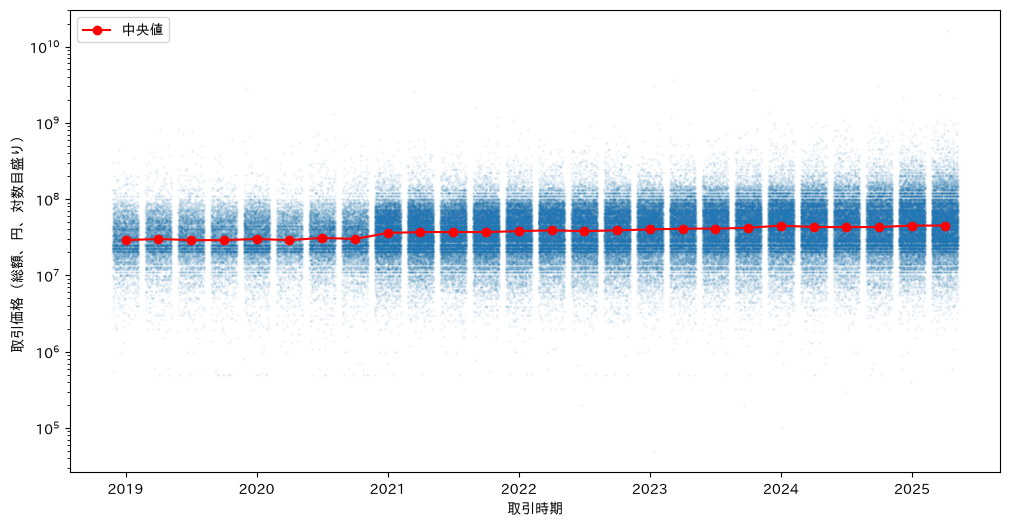

In [3]:
rng = np.random.default_rng(0)
jitter = rng.uniform(-0.1, 0.1, len(train))
median = train.groupby("時期_数値")[TARGET].median()

fig, ax = plt.subplots(figsize=(12, 6))
ax.scatter(train["時期_数値"] + jitter, train[TARGET], s=1, alpha=0.05)
ax.plot(median.index, median.values, color="red", marker="o", label="中央値")
ax.set_yscale("log")
ax.set_xlabel("取引時期")
ax.set_ylabel("取引価格（総額、円、対数目盛り）")
ax.legend()
plt.show()

### 四半期ごとの箱ひげ図

散布図では分かりにくい、ばらつきの変化を比べる。

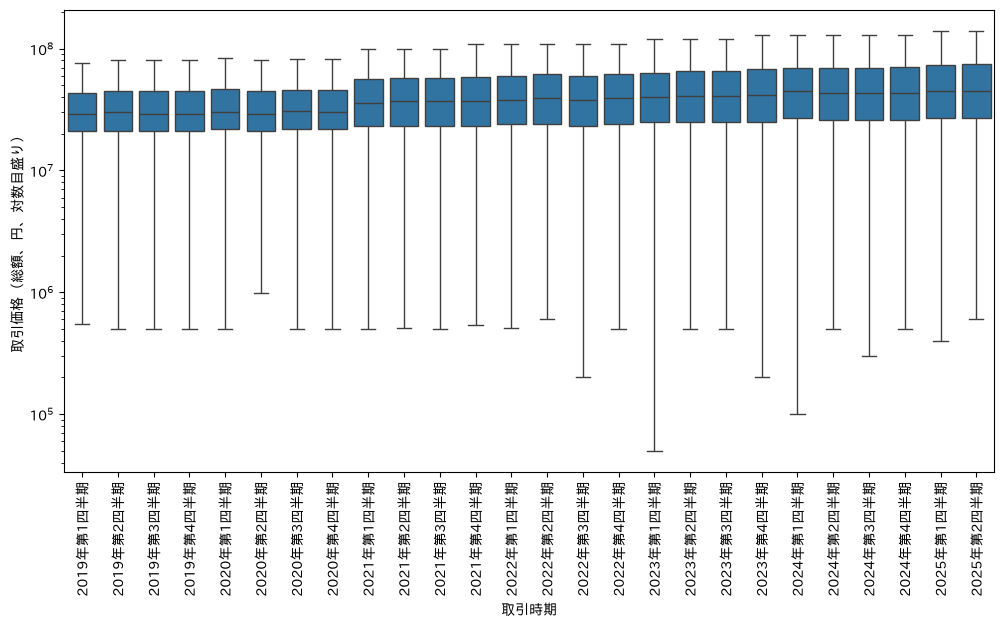

In [4]:
order = train.sort_values("時期_数値")["取引時期"].unique()

fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(data=train, x="取引時期", y=TARGET, order=order, showfliers=False, ax=ax)
ax.set_yscale("log")
ax.set_ylabel("取引価格（総額、円、対数目盛り）")
ax.tick_params(axis="x", rotation=90)
plt.show()